# CMP6202 – Notebook 04: Evaluation, improvements and conclusion

**Project:** Multi-class Classification for Cloud Network Intrusion Detection on AWS Using CSE-CIC-IDS2018

This notebook covers report sections **5** and **6**. Section 5 follows the seven steps of the report template. It
loads the searches fitted in notebook 03 and evaluates them on the held-out test set for the first time.

**Order of decisions.** Everything that chooses something was fixed on the training set beforehand: the
hyper-parameters (cross-validation in notebook 03), the ablation results (cross-validation below) and the rule for
picking the final model, which I state before looking at any test score:

> *Final model = the highest cross-validated macro F1. Models within one standard deviation of the best are treated
> as tied, and a tie is broken by the lower inference time.*

The test set only reports how the already-chosen models perform. Expensive analyses (ablations, learning curves, the
regularisation path) are cached under `models/`; set `NIDS_FORCE_RETRAIN=1` to recompute them.

In [1]:
# Google Colab setup. On a local machine this cell does nothing.
# On Colab: upload the project folder to Google Drive (README, "Run on Google Colab") and set PROJECT_DIR
# to its location. The cell mounts Drive, installs the pinned libraries and makes `nids` importable.
import os
import subprocess
import sys

if "google.colab" in sys.modules:
    from importlib.metadata import version

    from google.colab import drive

    drive.mount("/content/drive")
    PROJECT_DIR = "/content/drive/MyDrive/CMP6202_NIDS/Project"
    os.chdir(PROJECT_DIR)
    loaded = {name: version(dist) for name, dist in (("numpy", "numpy"), ("pandas", "pandas"), ("sklearn", "scikit-learn"))
              if name in sys.modules}
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements-colab.txt"], check=True)
    sys.path.insert(0, os.path.join(PROJECT_DIR, "src"))
    changed = [name for name, old in loaded.items()
               if old != version({"sklearn": "scikit-learn"}.get(name, name))]
    if changed:
        # A library that was already imported cannot be replaced in a running session.
        raise SystemExit(f"Upgraded {changed}: choose Runtime > Restart session, then run this cell again.")
    print("Running on Colab from", PROJECT_DIR)
else:
    print("Running locally; Colab setup skipped")

Running locally; Colab setup skipped


In [2]:
import os
import warnings

import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

from nids import config, data, evaluation, models, plotting

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
plotting.apply_style()
warnings.filterwarnings("ignore", category=FutureWarning)


def save_text(name: str, text: str) -> None:
    # I save every copy-ready paragraph so the report quotes the code's numbers; line breaks inside a
    # paragraph are joined so the text pastes into Word cleanly.
    paragraphs = [" ".join(block.split()) for block in text.strip().split("\n\n")]
    clean = "\n\n".join(paragraphs)
    (config.TEXT_DIR / f"{name}.txt").write_text(clean + "\n")
    print(clean, f"\n\n[{len(clean.split())} words → reports/text/{name}.txt]")


sample = data.load_sample()
split = data.load_split(sample)
data.assert_no_leakage(split)
X_train, y_train, X_test, y_test = split.X_train, split.y_train, split.X_test, split.y_test
runs = {name: models.load_or_run_search(name, X_train, y_train,
                                        force=os.environ.get("NIDS_FORCE_RETRAIN") == "1")
        for name in models.MODEL_NAMES}
print(f"Test set: {len(X_test):,} flows {y_test.value_counts().to_dict()}")

Test set: 15,000 flows {'Benign': 12715, 'SSH-Bruteforce': 2276, 'FTP-BruteForce': 9}


# 5 Evaluation and further modelling improvements

### Step 1: Model Selection

The project is a **classification** problem: the target `Label` is nominal with three classes (Benign,
FTP-BruteForce, SSH-Bruteforce), so regression metrics do not apply. I compare the eight classification algorithms
introduced in section 3.1, which cover linear, tree, bagging, boosting, distance-based, probabilistic, maximum-margin
and neural-network learners.

### Step 2: Data Preparation

The data were prepared before any model saw them (sections 3.3 and 4.1): 3,824 rows with infinite or missing rates and
5 rows with impossible negative values were dropped; 425,405 duplicate rows (40.7%) were removed, because duplicates
split across training and test sets inflate every score; `Timestamp` and `Dst Port` were excluded because they encode
how the labels were made; `Protocol` was one-hot encoded; constant columns were dropped and the numeric features
scaled; and the 75,000-flow sample was split 80/20, stratified by class. Everything that learns from data (scaling,
SMOTE, tuning) is fitted inside the pipeline on training folds only. The cell below shows one complete fitted pipeline.

In [3]:
runs[models.TREE].search.best_estimator_

,steps,"[('preprocess', ...), ('resample', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
Name,Type,Value
classes_,"ndarray[object](3,)","['Benign','FTP-BruteForce','SSH-Bruteforce']"
feature_names_in_,"ndarray[object](79,)","['Dst Port','Protocol','Timestamp',...,'Idle Std','Idle Max','Idle Min']"
n_features_in_,int,79
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('protocol', ...), ('numeric', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'


### Step 3: Model Development

Each tuned model was refitted on all 60,000 training flows (notebook 03). Here it predicts the 15,000 test flows,
which no step so far has used.

In [4]:
predictions, test_rows = {}, []
for name, run in runs.items():
    model = run.search.best_estimator_
    predictions[name] = model.predict(X_test)
    scores = evaluation.score_predictions(y_test, predictions[name])
    low, high = evaluation.bootstrap_interval(y_test, predictions[name], "f1_macro")
    test_rows.append({"model": name, **scores, "f1_macro_ci_low": low, "f1_macro_ci_high": high,
                      "test_errors": int((predictions[name] != y_test.to_numpy()).sum()),
                      "inference_ms_per_1000": evaluation.inference_ms_per_1000(model, X_test)})
test_results = pd.DataFrame(test_rows).set_index("model")
display(test_results.round(5))
test_results.round(6).to_csv(config.TABLES_DIR / "5_1_test_results.csv")

per_class = pd.concat({name: evaluation.per_class_report(y_test, p) for name, p in predictions.items()})
per_class.round(6).to_csv(config.TABLES_DIR / "5_1_test_per_class.csv")
test_errors = pd.DataFrame([
    {"model": n, "true": t, "predicted": p, "flows": int(((y_test.to_numpy() == t) & (pred == p)).sum())}
    for n, pred in predictions.items() for t in plotting.CLASS_ORDER for p in plotting.CLASS_ORDER if t != p
]).query("flows > 0")
display(test_errors.pivot_table(index="model", columns=["true", "predicted"], values="flows", fill_value=0)
        .reindex(models.MODEL_NAMES).fillna(0).astype(int))

,accuracy,f1_weighted,f1_macro,precision_macro,recall_macro,recall_ftp,f1_macro_ci_low,f1_macro_ci_high,test_errors,inference_ms_per_1000
model,,,,,,,,,,
Decision Tree,0.99987,0.99987,0.99983,0.99983,0.99983,1.0,0.99957,1.0,2,0.57719
Random Forest,0.99993,0.99994,0.98244,0.96667,0.99997,1.0,0.95234,1.0,1,2.96335
Gaussian Naive Bayes,0.99980,0.99980,0.99974,0.99992,0.99956,1.0,0.99939,1.0,3,1.18612
k-Nearest Neighbours,0.99993,0.99993,0.99991,0.99985,0.99997,1.0,0.99974,1.0,1,33.97592
Logistic Regression,0.99980,0.99981,0.96655,0.93925,0.99992,1.0,0.91659,1.0,3,1.26954
Support Vector Machine,0.99987,0.99987,0.98236,0.96652,0.99995,1.0,0.95191,1.0,2,2.18149
Gradient Boosting,1.00000,1.00000,1.00000,1.00000,1.00000,1.0,1.00000,1.0,0,8.04981
Multi-layer Perceptron,0.99993,0.99994,0.98244,0.96667,0.99997,1.0,0.95234,1.0,1,1.70775


true                           Benign                SSH-Bruteforce
predicted              FTP-BruteForce SSH-Bruteforce         Benign
model                                                              
Decision Tree                       0              1              1
Random Forest                       1              0              0
Gaussian Naive Bayes                0              0              3
k-Nearest Neighbours                0              1              0
Logistic Regression                 2              1              0
Support Vector Machine              1              1              0
Gradient Boosting                   0              0              0
Multi-layer Perceptron              1              0              0

### Step 4: Model Evaluation

**Performance metrics.** Accuracy, precision, recall and F1 on the test set, macro-averaged so that the nine
FTP-BruteForce flows count as much as the 12,715 benign ones, compared on the same metrics for every model.

--- Gradient Boosting ---
                precision    recall  f1-score   support

        Benign     1.0000    1.0000    1.0000     12715
FTP-BruteForce     1.0000    1.0000    1.0000         9
SSH-Bruteforce     1.0000    1.0000    1.0000      2276

      accuracy                         1.0000     15000
     macro avg     1.0000    1.0000    1.0000     15000
  weighted avg     1.0000    1.0000    1.0000     15000

--- Gaussian Naive Bayes ---
                precision    recall  f1-score   support

        Benign     0.9998    1.0000    0.9999     12715
FTP-BruteForce     1.0000    1.0000    1.0000         9
SSH-Bruteforce     1.0000    0.9987    0.9993      2276

      accuracy                         0.9998     15000
     macro avg     0.9999    0.9996    0.9997     15000
  weighted avg     0.9998    0.9998    0.9998     15000



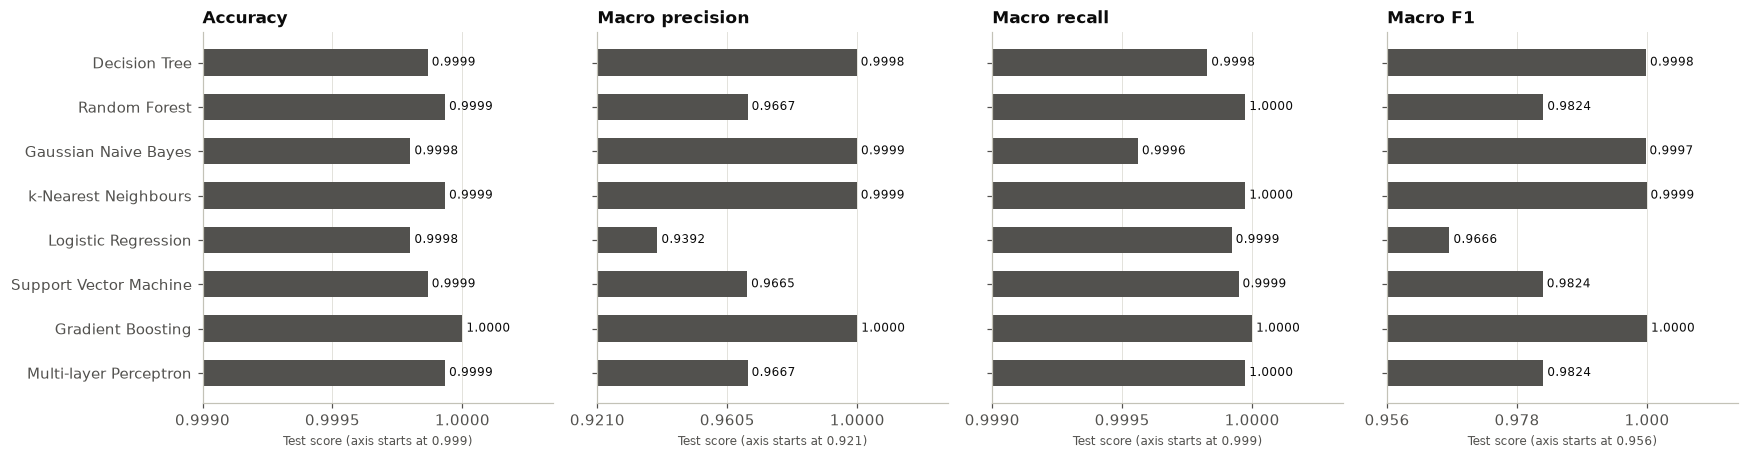

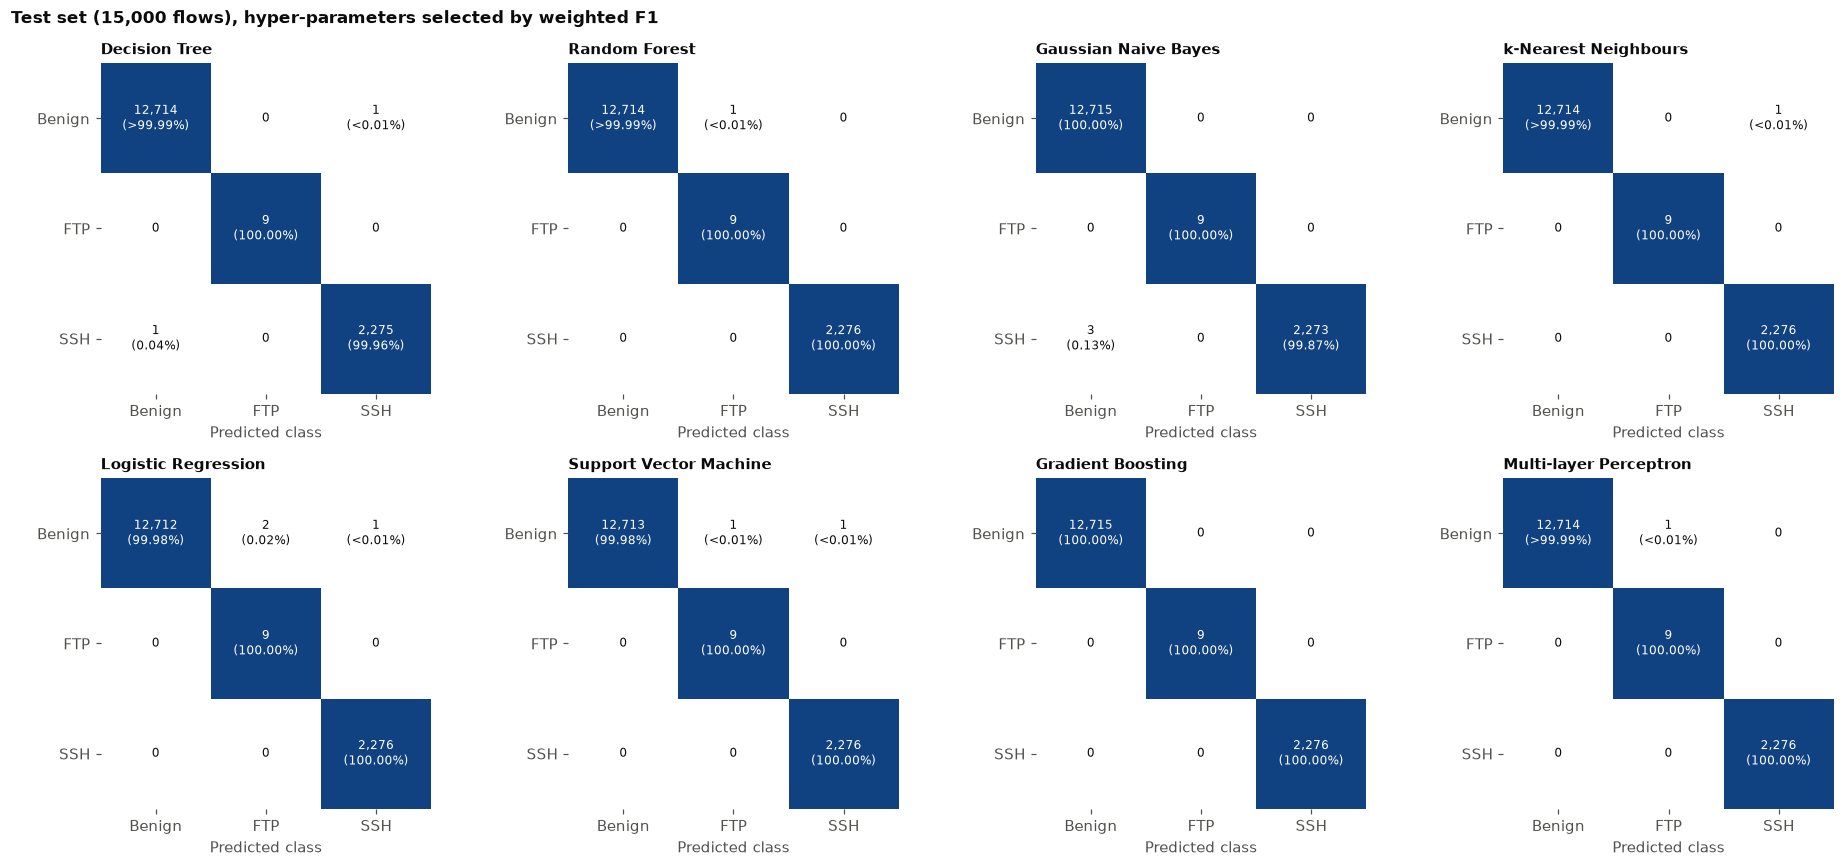

In [5]:
metric_labels = {"accuracy": "Accuracy", "precision_macro": "Macro precision",
                 "recall_macro": "Macro recall", "f1_macro": "Macro F1"}
fig = plotting.plot_metric_bars(test_results, metric_labels)
plotting.save_figure(fig, "5_4_test_metrics_by_model")

fig = plotting.plot_confusion_matrices({n: (y_test.to_numpy(), p) for n, p in predictions.items()},
                                       "Test set (15,000 flows), hyper-parameters selected by weighted F1")
plotting.save_figure(fig, "5_4_confusion_matrices_test")

# The classification report from the Week 4 lab, for the two models with the fewest and the most test errors.
for name in (test_results["test_errors"].idxmin(), test_results["test_errors"].idxmax()):
    print(f"--- {name} ---")
    print(classification_report(y_test, predictions[name], digits=4, zero_division=0))

### Step 5: Model Improvement

Three improvements, each decided on the training set by cross-validation: (i) re-selecting hyper-parameters by macro
F1 instead of the saturated weighted F1; (ii) feature selection through L1 regularisation; (iii) ablations that test
the shortcut features and the alternatives to SMOTE taught in the module (class weights, Tomek-link under-sampling).

**(i) Selecting hyper-parameters by macro F1.** Notebook 03 showed that weighted F1 is saturated, so tuning against
it picks almost arbitrarily. The search already scored every setting on macro F1, so no new search is needed: I take
the setting with the highest cross-validated macro F1 and refit it on the training set.

In [6]:
macro_rows, macro_predictions, macro_models = [], {}, {}
for name, run in runs.items():
    pipeline, params, index = evaluation.selected_pipeline(run, "f1_macro")
    model, fit_seconds = evaluation.fit_timed(pipeline, X_train, y_train)
    macro_models[name] = model
    macro_predictions[name] = model.predict(X_test)
    res = run.search.cv_results_
    scores = evaluation.score_predictions(y_test, macro_predictions[name])
    low, high = evaluation.bootstrap_interval(y_test, macro_predictions[name], "f1_macro")
    macro_rows.append({
        "model": name,
        "same setting as weighted F1": index == run.search.best_index_,
        "cv_f1_macro (weighted-selected)": res["mean_test_f1_macro"][run.search.best_index_],
        "cv_f1_macro (macro-selected)": res["mean_test_f1_macro"][index],
        "cv_f1_macro_std": res["std_test_f1_macro"][index],
        "test_f1_macro": scores["f1_macro"], "test_ci_low": low, "test_ci_high": high,
        "test_accuracy": scores["accuracy"], "test_precision_macro": scores["precision_macro"],
        "test_recall_macro": scores["recall_macro"], "test_recall_ftp": scores["recall_ftp"],
        "test_errors": int((macro_predictions[name] != y_test.to_numpy()).sum()),
        "fit_seconds": fit_seconds,
        "inference_ms_per_1000": evaluation.inference_ms_per_1000(model, X_test),
        "params": params,
    })
macro_selection = pd.DataFrame(macro_rows).set_index("model")
display(macro_selection.drop(columns="params").round(5))
macro_selection.drop(columns="params").round(6).to_csv(config.TABLES_DIR / "5_5_macro_selection.csv")

,same setting as weighted F1,cv_f1_macro (weighted-selected),cv_f1_macro (macro-selected),cv_f1_macro_std,test_f1_macro,test_ci_low,test_ci_high,test_accuracy,test_precision_macro,test_recall_macro,test_recall_ftp,test_errors,fit_seconds,inference_ms_per_1000
model,,,,,,,,,,,,,,
Decision Tree,False,0.99030,0.99534,0.00890,0.99991,0.99974,1.0,0.99993,0.99985,0.99997,1.0,1,0.45879,0.60301
Random Forest,True,0.99549,0.99549,0.00892,0.98244,0.95234,1.0,0.99993,0.96667,0.99997,1.0,1,3.87827,3.16959
Gaussian Naive Bayes,True,0.99952,0.99952,0.00029,0.99974,0.99939,1.0,0.99980,0.99992,0.99956,1.0,3,0.29234,1.17574
k-Nearest Neighbours,True,0.99998,0.99998,0.00004,0.99991,0.99974,1.0,0.99993,0.99985,0.99997,1.0,1,0.27462,33.91709
Logistic Regression,False,0.97928,0.98368,0.01551,0.98236,0.95200,1.0,0.99987,0.96652,0.99995,1.0,2,0.67043,1.31759
Support Vector Machine,True,0.99547,0.99547,0.00891,0.98236,0.95191,1.0,0.99987,0.96652,0.99995,1.0,2,0.69152,2.14740
Gradient Boosting,True,0.99551,0.99551,0.00893,1.00000,1.00000,1.0,1.00000,1.00000,1.00000,1.0,0,4.88860,8.28533
Multi-layer Perceptron,False,0.98765,0.99534,0.00884,0.98227,0.95182,1.0,0.99980,0.96649,0.99980,1.0,3,2.72751,0.91434


**(ii) Regularisation and feature selection (Week 9).** L2 (ridge) shrinks every coefficient of Logistic Regression;
L1 (lasso) can shrink some exactly to zero, which removes those features. In scikit-learn `C` is the inverse of the
lecture's α, so a smaller `C` means a stronger penalty. I keep the selected setting and vary only the penalty.

In [7]:
lr_params = macro_selection.loc[models.LOGREG, "params"]
regularisation, lr_coefficients = models.cached(
    "logistic_regression_l1_l2_path",
    lambda: evaluation.regularisation_comparison(runs[models.LOGREG], X_train, y_train, lr_params),
    X_train,
)
display(regularisation.round(4))
regularisation.round(6).to_csv(config.TABLES_DIR / "5_5_l1_vs_l2.csv", index=False)

# The strongest L1 penalty whose macro F1 stays within one standard deviation of the selected model.
selected_cv = macro_selection.loc[models.LOGREG, "cv_f1_macro (macro-selected)"]
selected_sd = macro_selection.loc[models.LOGREG, "cv_f1_macro_std"]
l1 = regularisation[regularisation["penalty"] == "L1 (lasso)"]
l1_ok = l1[l1["cv_f1_macro_mean"] >= selected_cv - selected_sd].sort_values("features_used")
sparse = l1_ok.iloc[0]
l2_same_c = regularisation[(regularisation["penalty"] == "L2 (ridge)") & (regularisation["C"] == sparse["C"])].iloc[0]
print(f"L1 with C = {sparse['C']:g} keeps {sparse['features_used']} of {sparse['features_used'] + sparse['features_removed']} "
      f"features, CV macro F1 {sparse['cv_f1_macro_mean']:.4f} (L2 at the same C: {l2_same_c['cv_f1_macro_mean']:.4f})")

,C,penalty,train_f1_macro,cv_f1_macro_mean,cv_f1_macro_std,features_removed,features_used
0,67.3225,L2 (ridge),0.9849,0.9837,0.0155,0,69
1,67.3225,L1 (lasso),0.9849,0.9837,0.0155,0,69
2,1.0000,L2 (ridge),0.9788,0.9793,0.0132,0,69
3,1.0000,L1 (lasso),0.9829,0.9837,0.0155,22,47
4,0.1000,L2 (ridge),0.9667,0.9671,0.0147,0,69
5,0.1000,L1 (lasso),0.9822,0.9830,0.0155,50,19
6,0.0100,L2 (ridge),0.9089,0.9098,0.0225,0,69
7,0.0100,L1 (lasso),0.9625,0.9650,0.0254,61,8


L1 with C = 0.1 keeps 19 of 69 features, CV macro F1 0.9830 (L2 at the same C: 0.9671)


In [8]:
# Which features does the sparse L1 model keep? I refit it once to list them.
sparse_model = clone(runs[models.LOGREG].search.estimator).set_params(**lr_params)
sparse_model.set_params(model=LogisticRegression(C=sparse["C"], l1_ratio=1.0, solver="saga", tol=1e-3,
                                                 max_iter=5_000, random_state=config.SEED))
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    sparse_model.fit(X_train, y_train)
coef = pd.DataFrame(sparse_model.named_steps["model"].coef_.T,
                    index=sparse_model.named_steps["preprocess"].get_feature_names_out(),
                    columns=sparse_model.named_steps["model"].classes_)
kept = coef[(coef.abs() > 1e-10).any(axis=1)]
kept = kept.reindex(kept.abs().max(axis=1).sort_values(ascending=False).index)
display(kept.round(3))
kept.round(6).to_csv(config.TABLES_DIR / "5_5_l1_selected_features.csv")
fingerprint_kept = [c for c in evaluation.HOST_FINGERPRINT_COLS if c in kept.index]
print("Host-fingerprint columns kept by L1:", fingerprint_kept)

,Benign,FTP-BruteForce,SSH-Bruteforce
Fwd Seg Size Min,-8.750,0.000,1.330
Fwd Act Data Pkts,-0.248,0.000,3.815
Fwd IAT Min,0.000,0.000,2.900
Bwd Pkt Len Max,0.000,0.000,1.702
Bwd IAT Min,0.939,0.000,-1.183
URG Flag Cnt,0.000,-0.308,0.837
Flow Duration,0.775,0.000,0.000
Active Mean,0.056,0.000,-0.576
Flow IAT Mean,0.467,0.000,-0.245
Bwd Pkts/s,-0.399,0.000,0.000


Host-fingerprint columns kept by L1: ['Fwd Seg Size Min']


**(iii) Ablations: shortcut features and class-imbalance handling.** Each variant changes exactly one thing in the
tuned pipeline and is scored with the same 5-fold cross-validation on the training set. Class weights only apply to
models that accept them (k-NN, Gaussian Naive Bayes and the MLP do not).

model,Decision Tree,Random Forest,Gaussian Naive Bayes,k-Nearest Neighbours,Logistic Regression,Support Vector Machine,Gradient Boosting,Multi-layer Perceptron
variant,,,,,,,,
main,0.9903,0.9955,0.9995,1.0000,0.9793,0.9955,0.9955,0.9876
with_dst_port,0.9960,0.9999,0.9995,1.0000,0.9916,0.9955,1.0000,0.9955
no_window_sizes,0.9902,0.9904,0.9912,0.9916,0.9793,0.9955,0.9843,0.9877
no_host_fingerprint,0.9903,0.9387,0.8287,0.8972,0.9317,0.9876,0.9792,0.9793
class_weight,0.9953,0.9955,NaN,NaN,0.9673,0.9954,0.9955,NaN
tomek_links,0.9954,0.9955,0.9995,1.0000,0.9837,0.9955,0.9904,0.9870
no_resampling,0.9954,0.9955,0.9995,1.0000,0.9837,0.9955,0.9904,0.9870


PosixPath('<project>/reports/figures/5_5_ablation_cv_macro_f1.png')

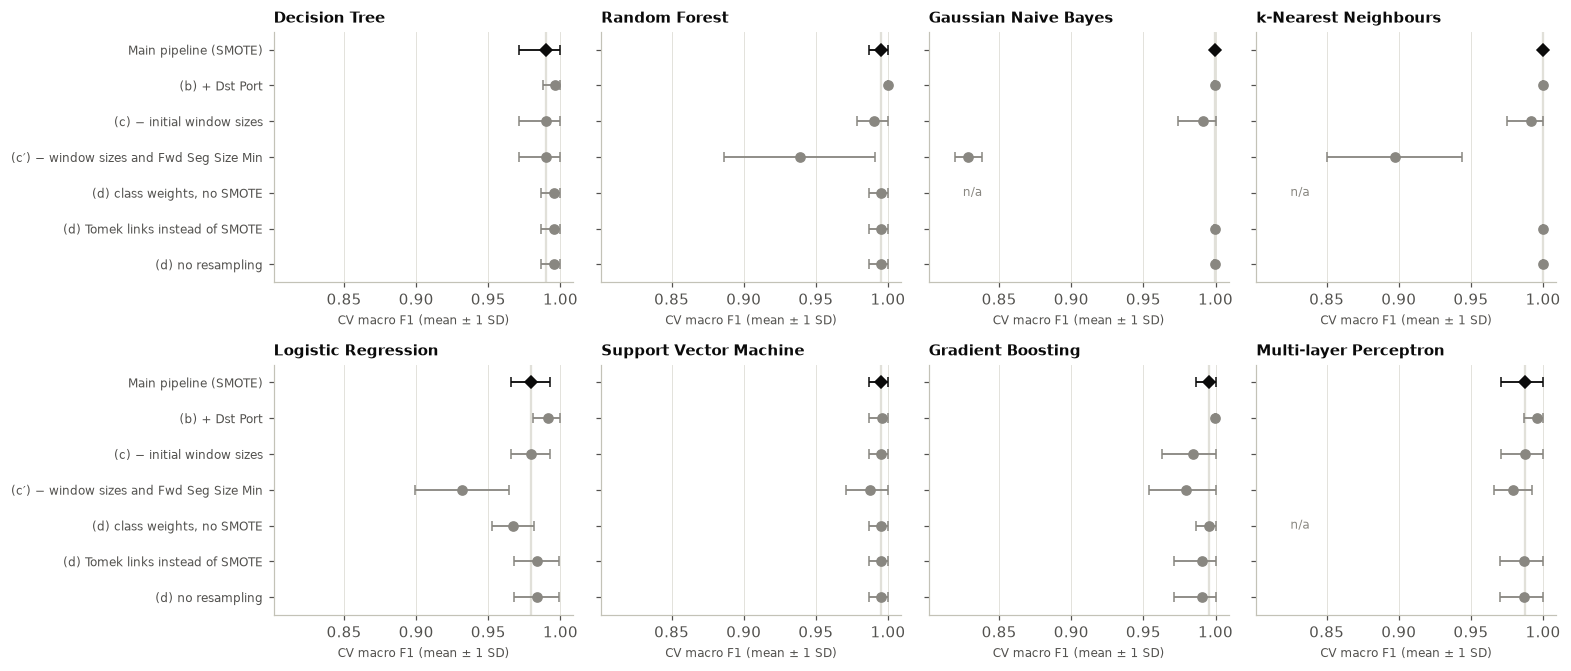

In [9]:
variant_labels = {
    "main": "Main pipeline (SMOTE)",
    "with_dst_port": "(b) + Dst Port",
    "no_window_sizes": "(c) − initial window sizes",
    "no_host_fingerprint": "(c′) − window sizes and Fwd Seg Size Min",
    "class_weight": "(d) class weights, no SMOTE",
    "tomek_links": "(d) Tomek links instead of SMOTE",
    "no_resampling": "(d) no resampling",
}


def run_ablation():
    rows = []
    for name, run in runs.items():
        for variant in variant_labels:
            if variant == "class_weight" and not models.supports_class_weight(name):
                rows.append({"model": name, "variant": variant,
                             **{f"{m}_{s}": np.nan for m in models.scorers() for s in ("mean", "std")}})
                continue
            pipeline, X_variant = evaluation.variant_pipeline(run, X_train, variant)
            rows.append({"model": name, "variant": variant, **evaluation.cross_validated(pipeline, X_variant, y_train)})
    return pd.DataFrame(rows)


ablation = models.cached("ablation_eight_models", run_ablation, X_train)
ablation.round(6).to_csv(config.TABLES_DIR / "5_5_ablation_cv.csv", index=False)
display(ablation.pivot(index="variant", columns="model", values="f1_macro_mean")
        .reindex(index=variant_labels, columns=models.MODEL_NAMES).round(4))
fig = plotting.plot_ablation(ablation, variant_labels)
plotting.save_figure(fig, "5_5_ablation_cv_macro_f1")

### Step 6: Validation

Three checks that the cross-validated scores can be trusted: (a) what a naive pipeline without de-duplication would
have reported; (b) whether the test scores fall in the range cross-validation predicted; (c) learning curves, which
show under- and over-fitting and whether more data of this kind would help.

**(a) What a naive pipeline would report.** I repeat sampling and splitting *without* de-duplication and measure how
many test flows already occur, identically, in the training set.

In [10]:
cleaned_rows = data.build_cleaned_rows()
naive_sample = data.stratified_sample(cleaned_rows, floor=0)   # floor 0 = purely proportional
naive_split = data.split_sample(naive_sample)
overlap = data.train_test_overlap(naive_split)
naive_model, _ = evaluation.variant_pipeline(runs[models.FOREST], naive_split.X_train, "no_resampling")
naive_model, _ = evaluation.fit_timed(naive_model, naive_split.X_train, naive_split.y_train)
naive_scores = evaluation.score_predictions(naive_split.y_test, naive_model.predict(naive_split.X_test))
naive_table = pd.DataFrame({
    "naive test flows": naive_split.y_test.value_counts(),
    "share already in training set": overlap,
})
display(naive_table.round(4))
print("Overall share of naive test flows already seen in training:",
      f"{data.flow_hash(naive_split.X_test).isin(set(data.flow_hash(naive_split.X_train))).mean():.2%}")
print("Random Forest on the naive split:", {k: round(v, 5) for k, v in naive_scores.items()})
naive_table.round(6).to_csv(config.TABLES_DIR / "5_6_naive_overlap.csv")
del cleaned_rows

,naive test flows,share already in training set
Benign,9531,0.1236
FTP-BruteForce,2776,0.9996
SSH-Bruteforce,2693,0.5095


Overall share of naive test flows already seen in training: 35.50%
Random Forest on the naive split: {'accuracy': 1.0, 'f1_weighted': 1.0, 'f1_macro': 1.0, 'precision_macro': 1.0, 'recall_macro': 1.0, 'recall_ftp': 1.0}


**(b) Cross-validation versus test.** Accuracy, weighted F1 and macro F1 with their uncertainty: ± 1 standard
deviation across folds for cross-validation, and a 95% stratified bootstrap interval for the test set.

cv_mean                          test                     
metric                 accuracy f1_macro f1_weighted accuracy f1_macro f1_weighted
model                                                                             
Decision Tree           0.99985  0.99030     0.99985  0.99987  0.99983     0.99987
Random Forest           0.99993  0.99549     0.99993  0.99993  0.98244     0.99994
Gaussian Naive Bayes    0.99963  0.99952     0.99963  0.99980  0.99974     0.99980
k-Nearest Neighbours    0.99998  0.99998     0.99998  0.99993  0.99991     0.99993
Logistic Regression     0.99985  0.97928     0.99985  0.99980  0.96655     0.99981
Support Vector Machine  0.99992  0.99547     0.99992  0.99987  0.98236     0.99987
Gradient Boosting       0.99995  0.99551     0.99995  1.00000  1.00000     1.00000
Multi-layer Perceptron  0.99988  0.98765     0.99989  0.99993  0.98244     0.99994

PosixPath('<project>/reports/figures/5_6_cv_vs_test.png')

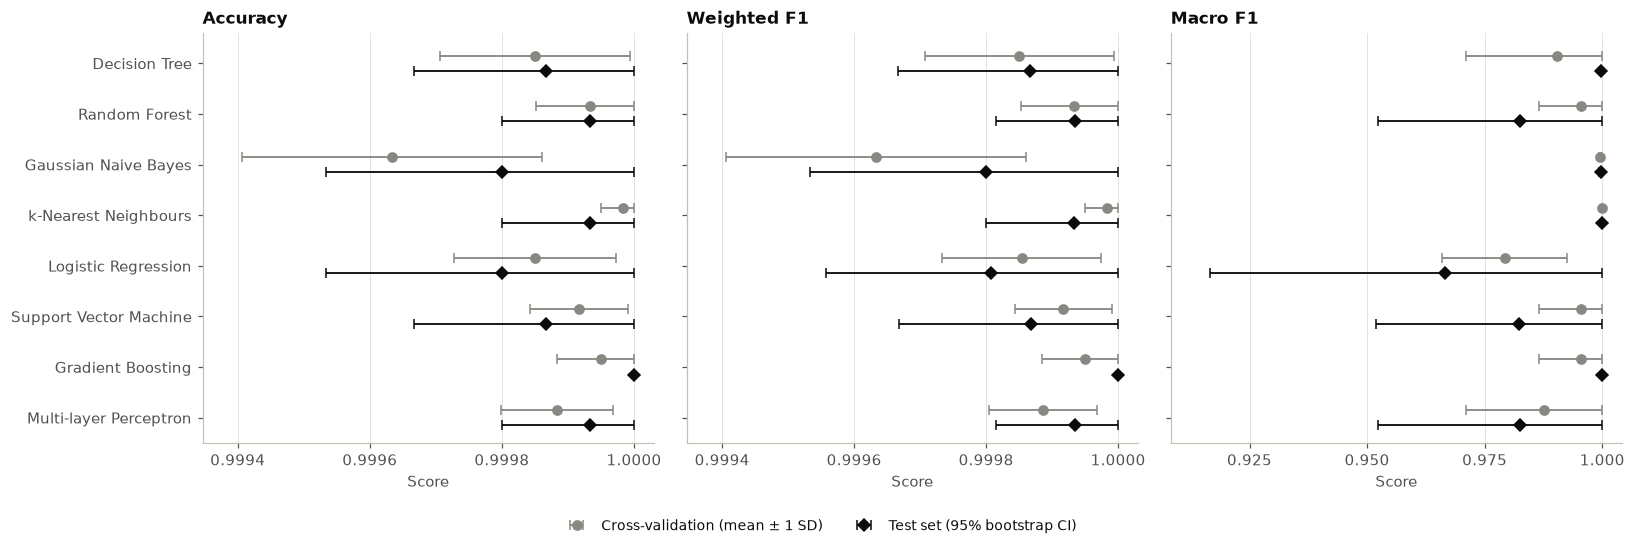

In [11]:
rows = []
for name, run in runs.items():
    res, best = run.search.cv_results_, run.search.best_index_
    for metric in ("accuracy", "f1_weighted", "f1_macro"):
        low, high = evaluation.bootstrap_interval(y_test, predictions[name], metric)
        rows.append({"model": name, "metric": metric,
                     "cv_mean": res[f"mean_test_{metric}"][best], "cv_std": res[f"std_test_{metric}"][best],
                     "test": test_results.loc[name, metric], "test_low": low, "test_high": high})
cv_vs_test = pd.DataFrame(rows)
display(cv_vs_test.pivot(index="model", columns="metric", values=["cv_mean", "test"]).reindex(models.MODEL_NAMES).round(5))
cv_vs_test.round(6).to_csv(config.TABLES_DIR / "5_6_cv_vs_test.csv", index=False)
fig = plotting.plot_cv_vs_test(cv_vs_test, {"accuracy": "Accuracy", "f1_weighted": "Weighted F1", "f1_macro": "Macro F1"})
plotting.save_figure(fig, "5_6_cv_vs_test")

**(c) Learning curves (Week 2: under- and over-fitting).** Training- and validation-fold macro F1 of each
macro-selected model as the training set grows from 30% to 100% of a fold.

,train − validation gap at full size,validation gain over the last step
Decision Tree,0.0045,0.0051
Random Forest,0.0045,0.0000
Gaussian Naive Bayes,0.0000,0.0000
k-Nearest Neighbours,0.0000,0.0000
Logistic Regression,0.0059,0.0006
Support Vector Machine,0.0045,0.0000
Gradient Boosting,0.0023,0.0000
Multi-layer Perceptron,0.0001,0.0038


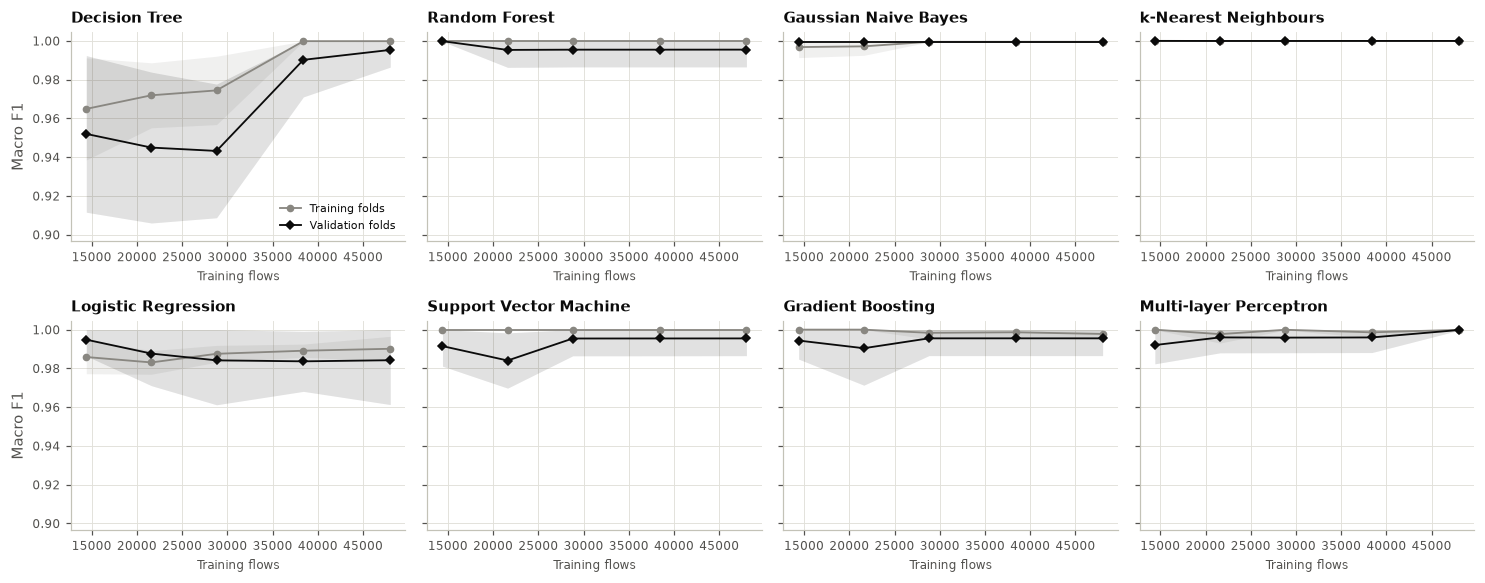

In [12]:
curves = models.cached(
    "learning_curves_eight_models",
    lambda: {name: evaluation.learning_curve_table(clone(macro_models[name]), X_train, y_train)
             for name in models.MODEL_NAMES},
    X_train,
)
fig = plotting.plot_learning_curves(curves)
plotting.save_figure(fig, "5_6_learning_curves")
curve_table = pd.concat(curves, names=["model", "row"]).reset_index(level="row", drop=True)
curve_table.round(6).to_csv(config.TABLES_DIR / "5_6_learning_curves.csv")
final_gap = {n: c["train_mean"].iloc[-1] - c["valid_mean"].iloc[-1] for n, c in curves.items()}
gain_last_step = {n: c["valid_mean"].iloc[-1] - c["valid_mean"].iloc[-2] for n, c in curves.items()}
display(pd.DataFrame({"train − validation gap at full size": final_gap,
                      "validation gain over the last step": gain_last_step}).round(4))

### Step 7: Comparative Analysis of Multiple Algorithms

All eight algorithms are compared with identical preprocessing, folds and metrics, using the macro-selected settings
from Step 5 (i). I apply the rule stated at the top of the notebook to their cross-validated macro F1.

,CV macro F1,Test accuracy,Test macro F1 [95% CI],"Test errors (of 15,000)",Test FTP recall,Training time (s),"Inference (ms / 1,000 flows)",Macro F1 drop without host fingerprint
Decision Tree,0.99534 ± 0.00890,0.99993,"0.9999 [0.9997, 1.0000]",1,1.0,0.46,0.60,0.0000
Random Forest,0.99549 ± 0.00892,0.99993,"0.9824 [0.9523, 1.0000]",1,1.0,3.88,3.17,0.0568
Gaussian Naive Bayes,0.99952 ± 0.00029,0.99980,"0.9997 [0.9994, 1.0000]",3,1.0,0.29,1.18,0.1709
k-Nearest Neighbours,0.99998 ± 0.00004,0.99993,"0.9999 [0.9997, 1.0000]",1,1.0,0.27,33.92,0.1028
Logistic Regression,0.98368 ± 0.01551,0.99987,"0.9824 [0.9520, 1.0000]",2,1.0,0.67,1.32,0.0476
Support Vector Machine,0.99547 ± 0.00891,0.99987,"0.9824 [0.9519, 1.0000]",2,1.0,0.69,2.15,0.0079
Gradient Boosting,0.99551 ± 0.00893,1.00000,"1.0000 [1.0000, 1.0000]",0,1.0,4.89,8.29,0.0163
Multi-layer Perceptron,0.99534 ± 0.00884,0.99980,"0.9823 [0.9518, 1.0000]",3,1.0,2.73,0.91,0.0084


Highest CV macro F1: k-Nearest Neighbours; tied within 1 SD: ['k-Nearest Neighbours']; final model (fastest of the tied): k-Nearest Neighbours


--- k-Nearest Neighbours (final model) ---
                precision    recall  f1-score   support

        Benign     1.0000    0.9999    1.0000     12715
FTP-BruteForce     1.0000    1.0000    1.0000         9
SSH-Bruteforce     0.9996    1.0000    0.9998      2276

      accuracy                         0.9999     15000
     macro avg     0.9999    1.0000    0.9999     15000
  weighted avg     0.9999    0.9999    0.9999     15000



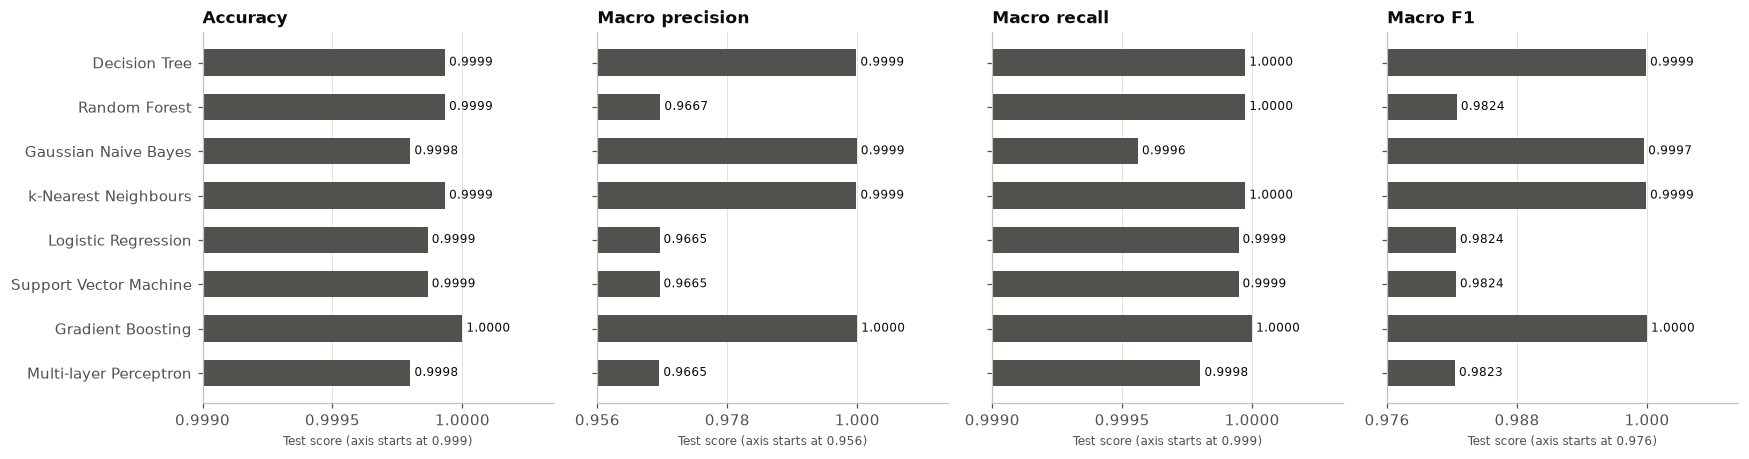

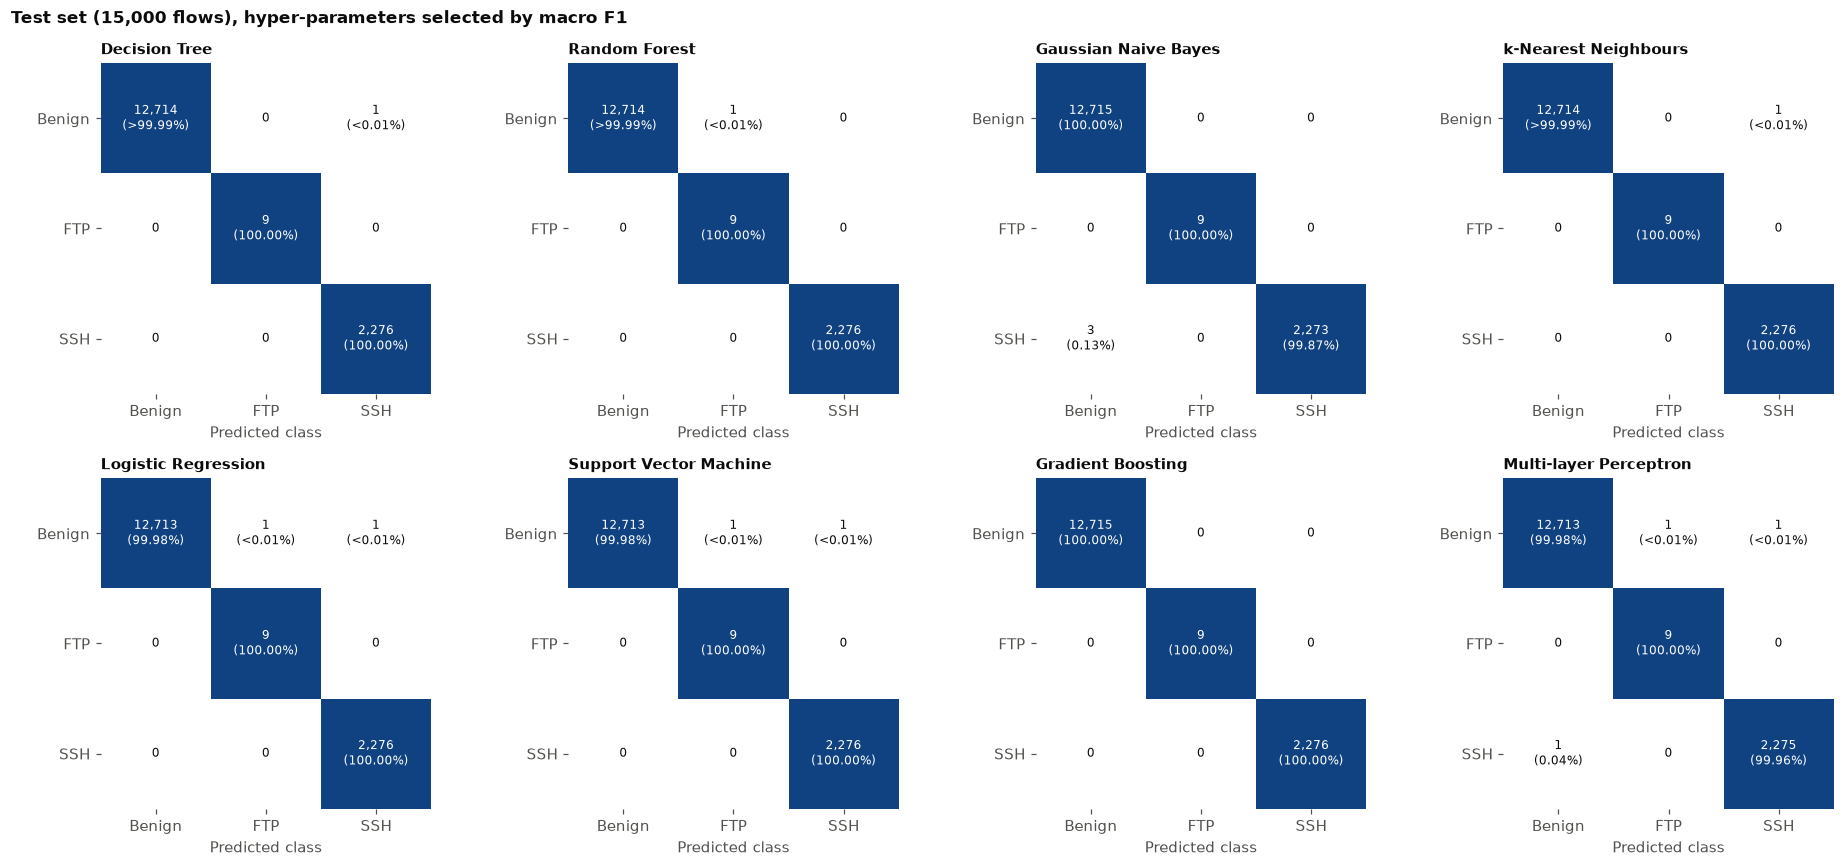

In [13]:
ms = macro_selection
ab = ablation.set_index(["model", "variant"])["f1_macro_mean"]
fingerprint_drop = {m: ab[(m, "main")] - ab[(m, "no_host_fingerprint")] for m in models.MODEL_NAMES}

cv_best = ms["cv_f1_macro (macro-selected)"]
leader = cv_best.idxmax()
tied = cv_best[cv_best >= cv_best[leader] - ms.loc[leader, "cv_f1_macro_std"]].index.tolist()
final_name = ms.loc[tied, "inference_ms_per_1000"].idxmin()

comparison = pd.DataFrame({
    # Five decimals for CV: k-NN's 0.99998 ± 0.00004 would otherwise print as a misleading "1.0 ± 0.0".
    "CV macro F1": cv_best.map("{:.5f}".format) + " ± " + ms["cv_f1_macro_std"].map("{:.5f}".format),
    "Test accuracy": ms["test_accuracy"].map("{:.5f}".format),
    "Test macro F1 [95% CI]": ms["test_f1_macro"].map("{:.4f}".format) + " [" +
                              ms["test_ci_low"].map("{:.4f}".format) + ", " + ms["test_ci_high"].map("{:.4f}".format) + "]",
    "Test errors (of 15,000)": ms["test_errors"],
    "Test FTP recall": ms["test_recall_ftp"],
    "Training time (s)": ms["fit_seconds"].round(2),
    "Inference (ms / 1,000 flows)": ms["inference_ms_per_1000"].round(2),
    "Macro F1 drop without host fingerprint": pd.Series(fingerprint_drop).round(4),
}).reindex(models.MODEL_NAMES)
display(comparison)
comparison.to_csv(config.TABLES_DIR / "5_7_final_comparison.csv")
print(f"Highest CV macro F1: {leader}; tied within 1 SD: {tied}; final model (fastest of the tied): {final_name}")

macro_metrics = ms.rename(columns={"test_accuracy": "accuracy", "test_precision_macro": "precision_macro",
                                   "test_recall_macro": "recall_macro", "test_f1_macro": "f1_macro"})
fig = plotting.plot_metric_bars(macro_metrics, metric_labels)
plotting.save_figure(fig, "5_7_comparison_bar_chart")
fig = plotting.plot_confusion_matrices({n: (y_test.to_numpy(), p) for n, p in macro_predictions.items()},
                                       "Test set (15,000 flows), hyper-parameters selected by macro F1")
plotting.save_figure(fig, "5_7_confusion_matrices_test_macro_selected")
print(f"--- {final_name} (final model) ---")
print(classification_report(y_test, macro_predictions[final_name], digits=4, zero_division=0))

**What the models learned.** The Decision Tree can be drawn and read directly (`plot_tree`, as in the Week 4 lab);
because it splits standardised inputs, I also print its rules with thresholds converted back to raw units. For the
Random Forest I report impurity importance (from training) and permutation importance on the test set.

if Fwd Seg Size Min <= 30.00:
|   → Benign
else (Fwd Seg Size Min > 30.00):
|   if Bwd Pkt Len Max <= 808.00:
|   |   if Bwd Pkts/s <= 14,693.26:
|   |   |   if Flow Pkts/s <= 8,903.76:
|   |   |   |   → Benign (subtree truncated)
|   |   |   else (Flow Pkts/s > 8,903.76):
|   |   |   |   → SSH-Bruteforce (subtree truncated)
|   |   else (Bwd Pkts/s > 14,693.26):
|   |   |   if Init Fwd Win Byts <= 17,537.50:
|   |   |   |   → Benign (subtree truncated)
|   |   |   else (Init Fwd Win Byts > 17,537.50):
|   |   |   |   → FTP-BruteForce
|   else (Bwd Pkt Len Max > 808.00):
|   |   → SSH-Bruteforce


,min,50%,max
Label,,,
Benign,0.0,20.0,40.0
FTP-BruteForce,40.0,40.0,40.0
SSH-Bruteforce,32.0,32.0,32.0


,impurity_importance,permutation_drop_f1_macro,permutation_std
Fwd Seg Size Min,0.1281,0.0110,0.0108
Init Fwd Win Byts,0.0756,0.0000,0.0000
Fwd Header Len,0.0718,-0.0035,0.0070
TotLen Fwd Pkts,0.0658,-0.0070,0.0086
Bwd Header Len,0.0656,0.0001,0.0000
Fwd Act Data Pkts,0.0656,0.0000,0.0000
Subflow Fwd Pkts,0.0597,-0.0140,0.0070
Tot Fwd Pkts,0.0515,0.0000,0.0000
Subflow Bwd Pkts,0.0441,0.0000,0.0000
Subflow Fwd Byts,0.0391,0.0000,0.0000


Root split of the Decision Tree: Fwd Seg Size Min


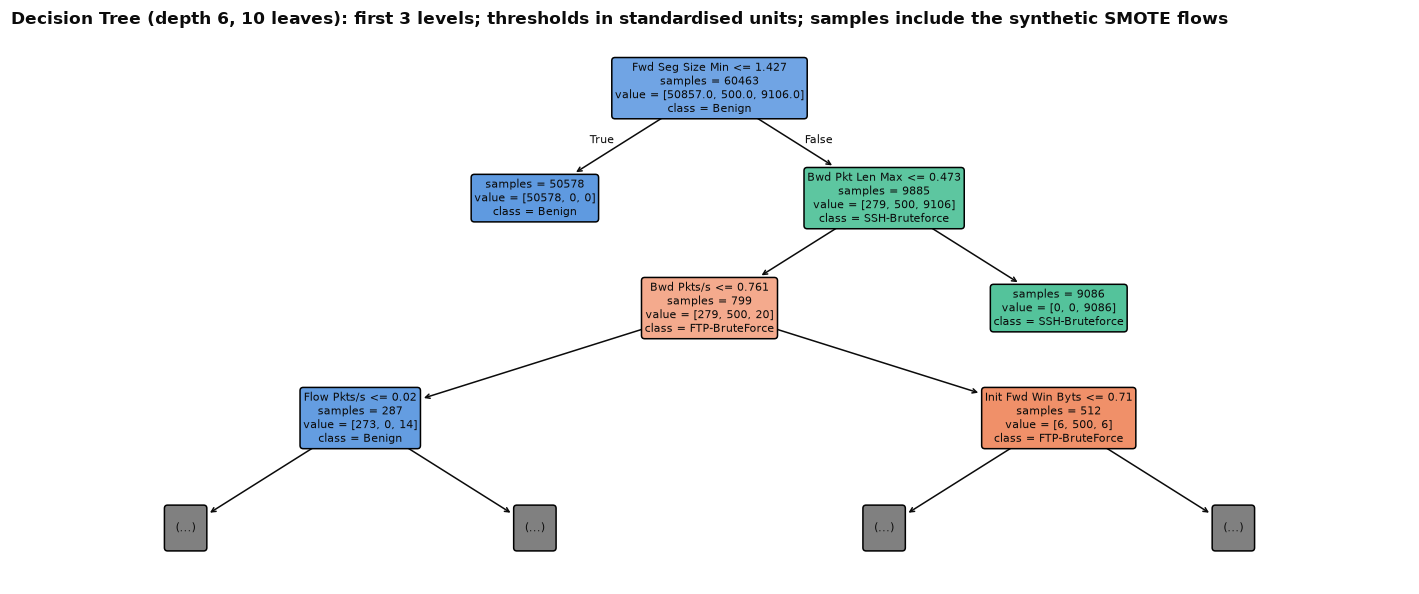

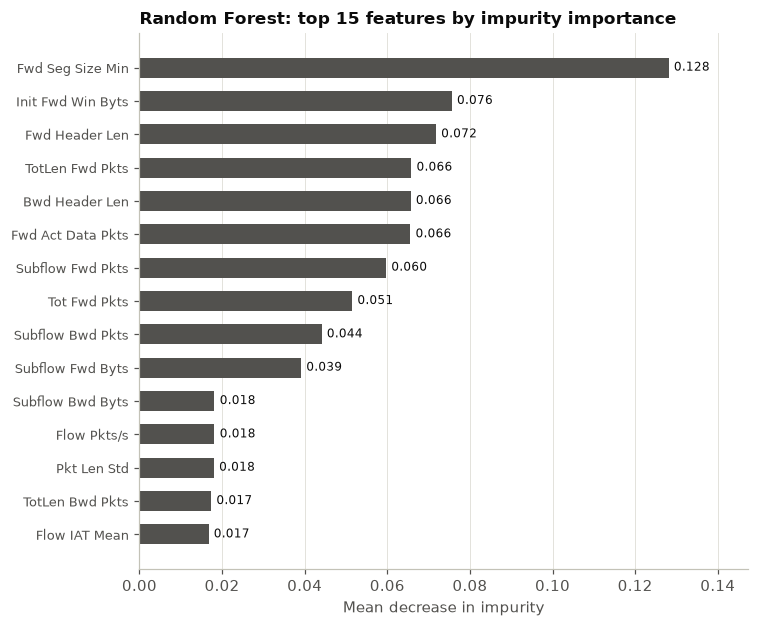

In [14]:
tree_model = macro_models[models.TREE]
tree = tree_model.named_steps["model"]
feature_names = list(tree_model.named_steps["preprocess"].get_feature_names_out())
fig = plotting.plot_decision_tree(tree_model, max_depth=3)
plotting.save_figure(fig, "5_7_decision_tree")
tree_rules = evaluation.tree_rules_in_original_units(tree_model, max_depth=4)
print(tree_rules)
(config.TABLES_DIR / "5_7_decision_tree_rules.txt").write_text(tree_rules + "\n")
root_feature = feature_names[tree.tree_.feature[0]]
seg_min = X_train.groupby(y_train, observed=True)["Fwd Seg Size Min"].describe()[["min", "50%", "max"]]
display(seg_min)

forest_model = macro_models[models.FOREST]
importance = evaluation.importance_table(forest_model, X_test, y_test, top=15)
display(importance.round(4))
importance.round(6).to_csv(config.TABLES_DIR / "5_7_random_forest_importance.csv")
fig = plotting.plot_importance(importance["impurity_importance"], "Random Forest: top 15 features by impurity importance",
                               "Mean decrease in impurity")
plotting.save_figure(fig, "5_7_random_forest_importance")
print("Root split of the Decision Tree:", root_feature)

**Strengths and weaknesses on this problem.** The table combines the measured numbers above with the property of each
algorithm that explains them.

In [15]:
notes = {
    models.TREE: "readable threshold rules; one tree can over-fit, controlled here by depth and leaf size",
    models.FOREST: "averaging lowers variance; slower and harder to read than one tree",
    models.NAIVE_BAYES: "fastest to train; its independence assumption is violated by the redundant features",
    models.KNN: "no training; stores all flows, so inference is the slowest and depends on near-copies in training",
    models.LOGREG: "linear boundary; needs scaling and the symlog transform to cope with heavy tails",
    models.SVM: "maximum-margin boundary; needs scaling, training cost grows quickly with data size",
    models.BOOSTING: "corrects errors tree by tree; strong on tabular data, slower inference than one tree",
    models.MLP: "learns non-linear features; needs scaling and more tuning, least interpretable",
}
strengths = pd.DataFrame({
    "CV macro F1": cv_best.round(5),
    "test errors": ms["test_errors"],
    "inference ms / 1,000": ms["inference_ms_per_1000"].round(2),
    "drop without host fingerprint": pd.Series(fingerprint_drop).round(4),
    "property that explains the result": pd.Series(notes),
}).reindex(models.MODEL_NAMES)
display(strengths)
strengths.to_csv(config.TABLES_DIR / "5_7_strengths_weaknesses.csv")

# A deployment recommendation is a separate question from the selection rule: among models within 0.01 macro
# F1 of the leader that do not depend on the attacking hosts' TCP values (drop < 0.01), take the fastest.
robust_candidates = [m for m in models.MODEL_NAMES
                     if cv_best[m] >= cv_best[leader] - 0.01 and fingerprint_drop[m] < 0.01]
recommended = ms.loc[robust_candidates, "inference_ms_per_1000"].idxmin() if robust_candidates else final_name
print("Robust candidates:", robust_candidates, "-> recommended for deployment:", recommended)

,CV macro F1,test errors,"inference ms / 1,000",drop without host fingerprint,property that explains the result
Decision Tree,0.99534,1,0.60,0.0000,readable threshold rules; one tree can over-fi...
Random Forest,0.99549,1,3.17,0.0568,averaging lowers variance; slower and harder t...
Gaussian Naive Bayes,0.99952,3,1.18,0.1709,fastest to train; its independence assumption ...
k-Nearest Neighbours,0.99998,1,33.92,0.1028,"no training; stores all flows, so inference is..."
Logistic Regression,0.98368,2,1.32,0.0476,linear boundary; needs scaling and the symlog ...
Support Vector Machine,0.99547,2,2.15,0.0079,"maximum-margin boundary; needs scaling, traini..."
Gradient Boosting,0.99551,0,8.29,0.0163,corrects errors tree by tree; strong on tabula...
Multi-layer Perceptron,0.99534,3,0.91,0.0084,learns non-linear features; needs scaling and ...


Robust candidates: ['Decision Tree', 'Support Vector Machine', 'Multi-layer Perceptron'] -> recommended for deployment: Decision Tree


In [16]:
r = test_results


def listing(names):
    # "A", "A and B", "A, B and C": lists of model names read as English.
    names = list(names)
    return names[0] if len(names) == 1 else ", ".join(names[:-1]) + " and " + names[-1] if names else ""


def plural(n, word):
    return f"{n} {word}" if n == 1 else f"{n} {word}s"


def delta(model, variant):
    return ab[(model, variant)] - ab[(model, "main")]

macro_cmp = cv_vs_test[cv_vs_test["metric"] == "f1_macro"].set_index("model")
below = [m for m in models.MODEL_NAMES if macro_cmp.loc[m, "test"] < macro_cmp.loc[m, "cv_mean"] - macro_cmp.loc[m, "cv_std"]]
overlaps = (macro_cmp["test_high"] >= macro_cmp["cv_mean"] - macro_cmp["cv_std"]).all()
generalisation = (
    "every test macro F1 falls within one standard deviation of its cross-validated mean" if not below else
    f"the test macro F1 of {listing(below)} {'falls' if len(below) == 1 else 'fall'} below one standard deviation of the cross-validated mean, "
    + ("yet every 95% bootstrap interval overlaps the cross-validated range" if overlaps else "and not every interval overlaps it")
)
ftp_found = {m: int(round(r.loc[m, "recall_ftp"] * 9)) for m in models.MODEL_NAMES}
port_gain = [m for m in models.MODEL_NAMES if delta(m, "with_dst_port") > 0]
reliant = sorted((m for m in models.MODEL_NAMES if fingerprint_drop[m] >= 0.01), key=lambda m: -fingerprint_drop[m])
not_reliant = [m for m in models.MODEL_NAMES if m not in reliant]
no_res = {m: delta(m, "no_resampling") for m in models.MODEL_NAMES}
tomek = {m: delta(m, "tomek_links") for m in models.MODEL_NAMES}
smote_helped = [m for m in models.MODEL_NAMES if no_res[m] < -ms.loc[m, "cv_f1_macro_std"]]
changed = [m for m in models.MODEL_NAMES if ms.loc[m, "test_errors"] != r.loc[m, "test_errors"]]
better_macro = [m for m in changed if ms.loc[m, "test_errors"] < r.loc[m, "test_errors"]]
largest_gap = max(final_gap, key=final_gap.get)
still_gaining = [m for m, g in gain_last_step.items() if g > 0.005]

save_text("5_evaluation", f'''
Test set (Steps 3–4). {"Every model detects all 9" if min(ftp_found.values()) == 9 else f"Every model detects at least {min(ftp_found.values())} of the 9"} FTP-BruteForce test flows and misclassifies
between {int(r["test_errors"].min())} and {int(r["test_errors"].max())} of 15,000 flows (accuracy {r["accuracy"].min():.4f}–{r["accuracy"].max():.4f};
Figures 5.1–5.2). Test macro F1 ranges from {r["f1_macro"].min():.4f} to {r["f1_macro"].max():.4f}, and {generalisation}.
With nine FTP flows, one false alarm lowers macro F1 by about 0.02, so the test set cannot rank the models.

Improvement (Step 5). (i) Re-selecting hyper-parameters by macro F1 instead of the saturated weighted F1 changed the
test errors of {listing(changed) or "no model"}{f", with fewer errors for {listing(better_macro)}" if better_macro else ""}. (ii) L1 regularisation
of Logistic Regression with C = {sparse["C"]:g} keeps {int(sparse["features_used"])} of {int(sparse["features_used"] + sparse["features_removed"])} features
at a cross-validated macro F1 of {sparse["cv_f1_macro_mean"]:.4f}, whereas L2 at the same C keeps all and scores
{l2_same_c["cv_f1_macro_mean"]:.4f}; the lasso therefore doubles as feature selection{f", and it keeps {', '.join(fingerprint_kept)}" if fingerprint_kept else ""}.
(iii) Adding Dst Port raises macro F1 for {len(port_gain)} of 8 models, confirming the port is a shortcut. Removing the
window sizes and Fwd Seg Size Min, which are constant within each attack and reflect the attacking hosts, lowers macro F1
by 0.01 or more for {listing(reliant) or "no model"}{f" (up to {fingerprint_drop[reliant[0]]:.3f} for {reliant[0]})" if reliant else ""}, but not for
{listing(not_reliant)}. SMOTE helped beyond one standard deviation for {listing(smote_helped) or "no model"}; relative to SMOTE, no
resampling changed macro F1 by {min(no_res.values()):+.4f} to {max(no_res.values()):+.4f} and Tomek links by {min(tomek.values()):+.4f} to {max(tomek.values()):+.4f}:
FTP-BruteForce is already separable, so synthetic flows mostly add false alarms.

Validation (Step 6). Without de-duplication {overlap.get("FTP-BruteForce", float("nan")):.2%} of FTP-BruteForce and
{overlap.get("SSH-Bruteforce", float("nan")):.1%} of SSH-Bruteforce test flows already occur identically in the training set, and the Random
Forest scores {naive_scores["f1_macro"]:.4f} macro F1 on that split, so a naive evaluation measures memory. The learning curves
(Figure 5.4) show training and validation scores converging; the largest final gap is {final_gap[largest_gap]:.4f}
({largest_gap}), and {"no model gains more than 0.005 from the last 20% of data" if not still_gaining else f"only {listing(still_gaining)} still {'gains' if len(still_gaining) == 1 else 'gain'} more than 0.005 from the last 20% of data"}.

Comparison (Step 7). By the rule fixed in advance, {leader} has the highest cross-validated macro F1
({cv_best[leader]:.5f}){f", {listing(t for t in tied if t != leader)} {'is' if len(tied) == 2 else 'are'} within one standard deviation" if len(tied) > 1 else " and no other model is within one standard deviation"},
so the final model is {final_name} (test macro F1 {ms.loc[final_name, "test_f1_macro"]:.4f}, {plural(ms.loc[final_name, "test_errors"], "error")},
{ms.loc[final_name, "inference_ms_per_1000"]:.2f} ms per 1,000 flows). {"For deployment I recommend the same model." if recommended == final_name else f"For deployment I recommend {recommended}: within 0.01 macro F1 of the leader, it does not depend on the attacking hosts' TCP values and runs in {ms.loc[recommended, 'inference_ms_per_1000']:.2f} ms per 1,000 flows."}
''')

Test set (Steps 3–4). Every model detects all 9 FTP-BruteForce test flows and misclassifies between 0 and 3 of 15,000 flows (accuracy 0.9998–1.0000; Figures 5.1–5.2). Test macro F1 ranges from 0.9666 to 1.0000, and the test macro F1 of Random Forest, k-Nearest Neighbours and Support Vector Machine fall below one standard deviation of the cross-validated mean, yet every 95% bootstrap interval overlaps the cross-validated range. With nine FTP flows, one false alarm lowers macro F1 by about 0.02, so the test set cannot rank the models.

Improvement (Step 5). (i) Re-selecting hyper-parameters by macro F1 instead of the saturated weighted F1 changed the test errors of Decision Tree, Logistic Regression and Multi-layer Perceptron, with fewer errors for Decision Tree and Logistic Regression. (ii) L1 regularisation of Logistic Regression with C = 0.1 keeps 19 of 69 features at a cross-validated macro F1 of 0.9830, whereas L2 at the same C keeps all and scores 0.9671; the lasso therefore double

# 6 Conclusion

## 6.1 Summary of results

In [17]:
save_text("6_1_summary", f'''
I built a reproducible pipeline that classifies network flows from one day of CSE-CIC-IDS2018 as Benign,
FTP-BruteForce or SSH-Bruteforce, and compared eight classification algorithms under identical conditions. The most
consequential step was data preparation: 99.98% of FTP-BruteForce rows were exact repeats, and the destination port and
timestamp encode how the labels were made; without de-duplication {overlap["FTP-BruteForce"]:.2%} of FTP-BruteForce test
flows would have been exact copies of training flows. On the cleaned data every algorithm separates both attacks almost
perfectly (at most {int(r["test_errors"].max())} errors in 15,000 test flows). For the three research questions: (RQ1) flow
statistics alone separate these brute-force attacks from benign traffic; (RQ2) {len(port_gain)} of 8 models gain from the
destination-port shortcut, and {listing(reliant) or "no model"} also lean on attacker-specific TCP values, while
{listing(not_reliant)} do not; (RQ3) SMOTE brought {"no consistent" if len(smote_helped) <= 1 else "some"} benefit, because the minority
class was already separable. The pre-registered rule selects {final_name}; because the models differ by a handful of
flows, cost, robustness and interpretability should decide deployment.

Recommended next steps for a security engineering lead: (1) treat these scores as an upper bound, since the data covers
one day and two attacks, each launched from one Kali Linux machine; (2) before deployment, validate on other
CSE-CIC-IDS2018 days and on locally captured traffic, using a time-based split; (3) deploy {recommended} as a lightweight
first-line filter in front of existing signature-based detection ({ms.loc[recommended, "inference_ms_per_1000"]:.2f} ms per
1,000 flows), retraining when new attack types are labelled; (4) monitor the false-alarm rate, the error that dominated here.
''')

I built a reproducible pipeline that classifies network flows from one day of CSE-CIC-IDS2018 as Benign, FTP-BruteForce or SSH-Bruteforce, and compared eight classification algorithms under identical conditions. The most consequential step was data preparation: 99.98% of FTP-BruteForce rows were exact repeats, and the destination port and timestamp encode how the labels were made; without de-duplication 99.96% of FTP-BruteForce test flows would have been exact copies of training flows. On the cleaned data every algorithm separates both attacks almost perfectly (at most 3 errors in 15,000 test flows). For the three research questions: (RQ1) flow statistics alone separate these brute-force attacks from benign traffic; (RQ2) 6 of 8 models gain from the destination-port shortcut, and Gaussian Naive Bayes, k-Nearest Neighbours, Random Forest, Logistic Regression and Gradient Boosting also lean on attacker-specific TCP values, while Decision Tree, Support Vector Machine and Multi-layer Perce

## 6.2 Reflection on Individual Learning

*This section must be written by me in my own words. The prompts and facts below are reminders of what happened during
the project; they are not text for the report.*

**Technical challenges to reflect on (with evidence in the notebooks):**

* The raw file looked balanced, but 99.98% of FTP rows were repeats; finding this needed hashing about one million rows
  (notebook 01). What did this teach me about trusting public datasets?
* Destination port and timestamp were part of the labelling procedure; the Timestamp column also used a 12-hour clock
  without AM/PM (notebook 01, section 1.1).
* Weighted F1 was saturated and could not rank models; I switched the selection metric to macro F1 (notebooks 03–04).
* SMOTE, which the lectures present as the remedy for imbalance, did not help here; the ablation showed why.
* Only nine FTP flows in the test set: bootstrap intervals showed that differences of one flow are not meaningful.
* Practical issues: one SVM search never finished because libsvm has no iteration limit by default (fixed with
  `max_iter`); the saga solver needed a looser tolerance to fit the L1 model in reasonable time; scikit-learn 1.8
  replaced `penalty` by `l1_ratio`; caching fitted searches; making results byte-for-byte reproducible.

**Certification evidence (insert each badge or certificate, its verification link and a short reflection):**

1. *Artificial Intelligence Fundamentals* – IBM SkillsBuild, digital badge via Credly, issued 12 November 2026 –
   [Credly badge URL] – [what I learnt and how it applies to this project]
2. *Introduction to Modern AI* – Cisco Networking Academy, digital badge via Credly, issued 12 November 2026 –
   [Credly badge URL] – [reflection]
3. *Intro to Machine Learning* – Kaggle, certificate, issued 12 November 2026 – [Kaggle certificate URL] –
   [reflection, e.g. validation data and under-/over-fitting with decision trees and random forests]
4. [Fourth certification from the module's list, e.g. Kaggle *Intermediate Machine Learning* (pipelines,
   cross-validation, data leakage)] – [link] – [reflection]